# EvoFlow use case: IFN-β-stimulated NK cells

This notebook is a complete, runnable example of the EvoFlow workflow. It asks
two related biological questions about **natural killer (NK) cells** responding
to **type I interferon**:

1. **Which mediators carry the IFN-β signal?** Starting from the type I
   interferon receptor (`IFNAR1`/`IFNAR2`) and the interferon-stimulated genes
   it induces, find the intracellular nodes whose removal most reduces that
   response.
2. **Which mediators drive NK activation and effector function?** Starting from
   the activating and inhibitory receptors NK cells use to sense other cells,
   find the nodes that connect them to granule and cytokine effectors.

Both questions use the same machinery: infer a signalling network with
**NicheNetPy**, weight it with **real expression data**, and search for node
knock-outs with the **EvoFlow genetic algorithm**.

## Running this notebook

Everything runs inside the container published with the project:

```bash
docker run --rm -p 8888:8888 ghcr.io/vergaju/evoflow:latest
```

The image ships Python, **NicheNetPy**, **pertpy** and EvoFlow, plus this
notebook under `vignettes/`. No local installation is required: open
`vignettes/use_case.ipynb` in JupyterLab and run the cells from top to bottom.

> **First run.** NicheNetPy downloads its reference model from Zenodo (about
> 600 MB) and `pertpy` downloads the `kang_2018` dataset (about 40 MB). Both are
> cached, so later runs are much faster.

## Experimental system

[Kang et al. (2018)](https://doi.org/10.1038/nbt.4042) profiled PBMCs from eight
donors, each with a control sample and a sample stimulated with **IFN-β for six
hours**. We keep the **NK cells** and, for modelling, only the **stimulated**
condition (`label == "stim"`): the question is about the response to interferon,
not the resting state. Control cells are used only to show how IFN-β changes
gene detection.

## What you will learn

- how to turn a receptor/target panel into a weighted prior with NicheNetPy;
- how single-cell expression becomes per-gene `percolation` values;
- how EvoFlow builds the max-flow topology and what the GA optimises;
- how to read the Pareto front (`Flow`, `Node`, `Redundancy`) and turn a
  solution into an experimental hypothesis.

Figures are drawn at 96 DPI with small figure sizes so the committed notebook
stays lightweight in git.

## 0. Setup and imports

In [1]:
import os
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
from IPython.display import display

import EvoFlow

# Keep every figure small and low-resolution (the notebook is committed to git).
plt.rcParams["figure.dpi"] = 96
plt.rcParams["savefig.dpi"] = 96
plt.rcParams["figure.figsize"] = (6, 4)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

WORKDIR = Path.cwd()
INPUT_DIR = WORKDIR / "inputs"
OUTPUT_DIR = WORKDIR / "outputs"
NICHENET_DIR = OUTPUT_DIR / "nichenet"
for directory in (INPUT_DIR, OUTPUT_DIR, NICHENET_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("EvoFlow:", EvoFlow.__version__)
print("Python:", sys.version.split()[0])
print("Working directory:", Path.cwd())

EvoFlow: 1.0.0
Python: 3.13.18
Working directory: /home/jovyan/work/vignettes


### A short glossary

| Term | Meaning in EvoFlow |
| --- | --- |
| **percolation** | One number in (0, 1] per gene describing how broadly it is expressed; it scales edge capacities. |
| **capacity** | The maximum "amount of signal" an edge can carry: `weight × (percolation_u + percolation_v) / 2`. |
| **max-flow / min-cut** | The largest signal flow from the receptors (source) to the targets (sink). A knock-out is useful when it lowers that maximum. |
| **redundancy** | Number of strongly connected components left in the graph. High redundancy means many alternative routes survive. |
| **Pareto front** | The solutions where no objective can improve without worsening another. EvoFlow reports four representative points. |

## 1. Data: NK cells under IFN-β stimulation

EvoFlow needs one number per gene to decide how "open" a pathway is. Several
statistics of the expression matrix are available:

- `nonzero_ratio` — fraction of cells in which the gene is detected (default,
  and the most robust to single-cell dropout);
- `mean` — mean expression across cells;
- `median` — median expression;
- `p90` — 90th percentile, robust to a few very highly expressed cells;
- `max` — highest observed value.

Each statistic is rescaled by its own maximum, so percolation always lies in
(0, 1] and cannot overflow the integer capacities used by the max-flow solver.
Here we use `mean` on raw UMI counts, which rewards both detection and
abundance; `nonzero_ratio` is the safer choice when dropout dominates.

We model **stimulated** cells only: IFN-β rewires expression, so capacities
calibrated on resting NK cells would describe a different biological state.

In [2]:
import pertpy as pt

adata = pt.dt.kang_2018()
print(adata)
display(adata.obs[["cell_type", "label", "replicate"]].head())
display(adata.obs["cell_type"].value_counts())

/opt/conda/lib/python3.13/site-packages/pertpy/data/_datasets.py:407: FutureWarning: Import from `scanpy.io` instead
  adata = sc.read_h5ad(output_file_path)


AnnData object with n_obs × n_vars = 24673 × 15706
    obs: 'nCount_RNA', 'nFeature_RNA', 'tsne1', 'tsne2', 'label', 'cluster', 'cell_type', 'replicate', 'nCount_SCT', 'nFeature_SCT', 'integrated_snn_res.0.4', 'seurat_clusters'
    var: 'name'
    obsm: 'X_pca', 'X_umap'
    layers: None (.X)


,cell_type,label,replicate
index,,,
AAACATACATTTCC-1,CD14+ Monocytes,ctrl,patient_1016
AAACATACCAGAAA-1,CD14+ Monocytes,ctrl,patient_1256
AAACATACCATGCA-1,CD4 T cells,ctrl,patient_1488
AAACATACCTCGCT-1,CD14+ Monocytes,ctrl,patient_1256
AAACATACCTGGTA-1,Dendritic cells,ctrl,patient_1039


cell_type
CD4 T cells          11238
CD14+ Monocytes       5697
B cells               2651
NK cells              1716
CD8 T cells           1621
FCGR3A+ Monocytes     1089
Dendritic cells        529
Megakaryocytes         132
Name: count, dtype: int64

`kang_2018` is a single AnnData object: 24,673 cells × 15,706 genes. `obs`
contains the donor (`replicate`), the condition (`label`, either `ctrl` or
`stim`) and the annotated `cell_type`. NK cells are 1,716 of the 24,673 cells.

In [3]:
nk_all = adata[adata.obs["cell_type"].astype(str) == "NK cells"].copy()
nk_all.obs["condition"] = nk_all.obs["label"].astype(str)
print("NK cells per condition:")
display(nk_all.obs["condition"].value_counts())

NK cells per condition:


condition
stim    861
ctrl    855
Name: count, dtype: int64

Keeping only NK cells leaves about 860 cells per condition — enough to estimate
detection rates reliably, and small enough to model quickly.

### Sanity check: did the stimulation work?

Before trusting any network, check that the data behaves as expected. The panel
below groups all cells by condition and shows two blocks of genes:

- **NK markers** (`NKG7`, `GNLY`, `PRF1`, `GZMB`) — should be concentrated in
  the NK compartment, confirming the cell-type annotation;
- **IFN-β response genes** (`ISG15`, `IFIT1`, `MX1`, `TNFSF10`) — should be
  clearly higher in the `stim` samples, confirming that the stimulation is
  visible in the matrix.

Normalization (`normalize_total` + `log1p`) is applied to a **copy** used only
for plotting: the exported count matrix keeps the raw values.

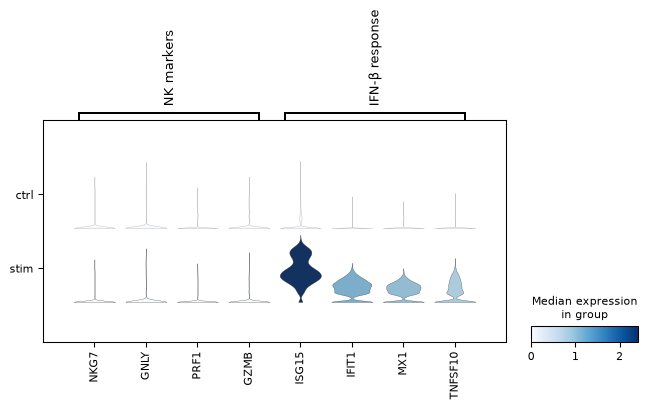

In [4]:
marker_dict = {
    "NK markers": [g for g in ["NKG7", "GNLY", "PRF1", "GZMB"] if g in adata.var_names],
    "IFN-β response": [
        g for g in ["ISG15", "IFIT1", "MX1", "TNFSF10"] if g in adata.var_names
    ],
}
marker_dict = {k: v for k, v in marker_dict.items() if v}

# Normalise a copy: the raw counts in `adata` and `nk_all` are kept for EvoFlow.
adata_plot = adata.copy()
sc.pp.normalize_total(adata_plot)
sc.pp.log1p(adata_plot)

if marker_dict:
    sc.pl.stacked_violin(
        adata_plot,
        marker_dict,
        groupby="label",
        figsize=(8, 3),
        swap_axes=False,
    )

Look for a clean split: the NK block should be flat in non-NK cells and high in
NK cells, while the interferon block should shift upwards in every `stim`
group. If either pattern is missing, the network would be built on the wrong
cells or the wrong condition.

## 2. Use case A — the IFN-β response

NicheNet works from a **receiver-cell** perspective: you specify the receptors
the cell uses to sense its environment and the genes whose activity you want to
explain. NicheNet then extracts the highest-weight signalling paths that connect
the matching ligands to those targets.

For this first question the receiver is an NK cell, the receptors are the type I
interferon receptor, and the targets are the interferon-stimulated genes whose
induction defines the response.

### 2.1 Receptor and target panel

| Gene(s) | Role |
| --- | --- |
| `IFNAR1`, `IFNAR2` | The two chains of the type I IFN receptor — the direct entry point for IFN-β (and the IFN-α family). |
| `ISG15`, `IFIT1`, `IFIT2`, `IFIT3`, `IFI6` | Canonical interferon-stimulated genes: antiviral effectors and amplifiers of the response. |
| `MX1`, `MX2`, `OAS1`, `OAS2`, `OAS3`, `RSAD2` | Interferon-induced restriction factors that block viral replication. |
| `IFITM1`, `IFITM2`, `IFITM3` | Interferon-induced transmembrane proteins that inhibit viral entry. |

The candidate ligands are not hard-coded: any ligand in NicheNet's
ligand–receptor network whose receptor appears in the panel becomes a candidate.
With `IFNAR1`/`IFNAR2` that automatically includes IFN-β itself (`IFNB1`), the
IFN-α family and a few other IFNAR ligands.

In [ ]:
ifn_endpoints = pd.read_csv("inputs/ifn_response_endpoints_unique.csv")

The panel is read from `inputs/ifn_response_endpoints_unique.csv`, so you can
edit the CSV (or point the notebook at your own file) without touching the code
below. Empty cells are dropped, which is why one column can be longer than the
other.

In [6]:
SAMPLE = "nk_ifnb_stim"

# Receptors that define the IFN-β input of the receiver.
RECEPTORS = list(ifn_endpoints["receptors"].dropna().values)

# Interferon-stimulated genes used as read-outs of the response.
TARGETS = list(ifn_endpoints["targets"].dropna().values)

### 2.2 Download the NicheNet reference model

NicheNet ships (i) a ligand–target matrix used to score ligands, and (ii) two
weighted networks: ligand → signalling → transcription factor (`lr_sig`) and
transcription factor → target (`gr`). They are published on Zenodo and cached
under `outputs/nichenet/reference/`.

Downloads are written to a `.part` file first and renamed only when complete,
so an interrupted transfer cannot leave a truncated cache behind.

In [7]:
from urllib.request import urlopen

REFERENCE_FILES = {
    "ltf_matrix_human.pkl": (
        "https://zenodo.org/records/17061000/files/ltf_matrix_human.pkl"
    ),
    "nichenet_human.pkl": (
        "https://zenodo.org/records/17061000/files/nichenet_human.pkl"
    ),
}
reference_dir = NICHENET_DIR / "reference"
reference_dir.mkdir(parents=True, exist_ok=True)

for filename, url in REFERENCE_FILES.items():
    destination = reference_dir / filename
    if destination.exists():
        continue
    print(f"downloading {filename} ...")
    partial = destination.with_suffix(destination.suffix + ".part")
    with urlopen(url, timeout=600) as response, open(partial, "wb") as handle:
        while chunk := response.read(1 << 20):
            handle.write(chunk)
    partial.replace(destination)
    print(f"saved {destination} ({destination.stat().st_size / 1e6:.0f} MB)")

Two edge tables are produced:

- **`tf_signaling`** — ligand → receptor → kinase/adaptor paths that reach the
  transcription factors;
- **`tf_regulatory`** — transcription factor → target edges.

`top_n_regulators=10` keeps the ten best-supported regulators for each
ligand–target pair. Lower values give a smaller, more conservative network;
higher values add alternative routes, which is exactly the redundancy the GA
has to reason about.

Only targets present in NicheNet's gene-regulatory network can be modelled, so
the panel is filtered against it at runtime and any missing gene is reported.

In [8]:
from nichenetpy.visualization import get_ligand_signaling_path

with open(reference_dir / "ltf_matrix_human.pkl", "rb") as handle:
    ltf = pickle.load(handle)
with open(reference_dir / "nichenet_human.pkl", "rb") as handle:
    model = pickle.load(handle)

lr_sig = pd.DataFrame(model["lr_sig"]._mapping, columns=["from", "to", "weight"])
gr = pd.DataFrame(model["gr"]._mapping, columns=["from", "to", "weight"])
lr_network = pd.DataFrame(model["lr_network"]._mapping, columns=["from", "to"])

ligands = sorted(set(lr_network.loc[lr_network["to"].isin(RECEPTORS), "from"]))
gr_targets = set(gr["to"].unique())
targets = [target for target in TARGETS if target in gr_targets]
print(f"{len(ligands)} candidate ligands: {ligands}")
print(f"targets kept: {targets}")
if not ligands or not targets:
    raise RuntimeError(
        "No ligands or targets remain for the selected receptors. "
        "Adjust RECEPTORS/TARGETS."
    )

19 candidate ligands: ['IFNA1', 'IFNA10', 'IFNA13', 'IFNA14', 'IFNA16', 'IFNA17', 'IFNA2', 'IFNA21', 'IFNA4', 'IFNA5', 'IFNA6', 'IFNA7', 'IFNA8', 'IFNB1', 'IFNE', 'IFNK', 'IFNW1', 'IL36G', 'MMP9']
targets kept: ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'IFI6', 'MX1', 'MX2', 'OAS1', 'OAS2', 'OAS3', 'RSAD2', 'IFITM1', 'IFITM2', 'IFITM3']


In [9]:
tf_signaling, tf_regulatory = get_ligand_signaling_path(
    ltf["mat"],
    ligands,
    targets,
    all_ligands=ltf["row_names"],
    all_targets=ltf["col_names"],
    lr_sig=lr_sig,
    gr=gr,
    top_n_regulators=10,
    minmax_scaling=False,
)

network_df = pd.concat(
    [
        tf_signaling.assign(layer="signaling"),
        tf_regulatory.assign(layer="regulatory"),
    ],
    ignore_index=True,
)
network_nodes = set(network_df["from"]) | set(network_df["to"])
print(f"net: {len(network_df)} edges, {len(network_nodes)} nodes")
print("receptors in network:", [r for r in RECEPTORS if r in network_nodes])
print("targets in network:", [t for t in targets if t in network_nodes])
display(network_df.head())

net: 4948 edges, 152 nodes
receptors in network: ['IFNAR1', 'IFNAR2']
targets in network: ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'IFI6', 'MX1', 'MX2', 'OAS1', 'OAS2', 'OAS3', 'RSAD2', 'IFITM1', 'IFITM2', 'IFITM3']


,from,to,weight,layer
0,ABL1,APP,0.692251,signaling
1,ABL1,AR,0.127557,signaling
2,ABL1,BRCA1,0.723338,signaling
3,ABL1,BTK,1.183869,signaling
4,ABL1,CD44,0.139222,signaling


EvoFlow reports solutions by node type, so every node needs a label. Receptors
are recognised from the ligand–receptor network, transcriptional regulators from
the gene-regulatory network, the requested ligands and targets are labelled
explicitly, and everything else (kinases, adaptors, co-factors) becomes a
*signalling mediator*.

The network and annotation are written as TSV files — the input format of the
`evoflow` command-line interface.

In [10]:
receptor_genes = set(lr_network["to"])
regulator_genes = set(gr["from"])
ligand_set, target_set = set(ligands), set(targets)

rows = []
for gene in sorted(network_nodes):
    if gene in ligand_set:
        annotation = "ligand"
    elif gene in target_set:
        annotation = "target"
    elif gene in receptor_genes:
        annotation = "receptor"
    elif gene in regulator_genes:
        annotation = "transcriptional regulator"
    else:
        annotation = "signaling mediator"
    rows.append({"gene": gene, "annotation": annotation})
annotation_df = pd.DataFrame(rows)

network_path = NICHENET_DIR / f"{SAMPLE}_weighted_signaling_network.tsv"
annotation_path = NICHENET_DIR / f"{SAMPLE}_annotation_table.tsv"
network_df.to_csv(network_path, sep="\t", index=False)
annotation_df.to_csv(annotation_path, sep="\t", index=False)

print("saved", network_path.name, "and", annotation_path.name)
display(annotation_df["annotation"].value_counts())

saved nk_ifnb_stim_weighted_signaling_network.tsv and nk_ifnb_stim_annotation_table.tsv


annotation
transcriptional regulator    107
ligand                        19
target                        14
receptor                      12
Name: count, dtype: int64

### 2.3 How IFN-β changes the network genes

Capacities are computed from stimulated cells, but it is worth seeing what that
choice changes. The plot below compares, for every network gene, the fraction of
NK cells in which it is detected in `stim` versus `ctrl`.

Bars to the right are genes switched on (or up) by IFN-β — typically interferon-
stimulated genes; bars to the left are genes switched off. This is the
expression-level counterpart of the network question.

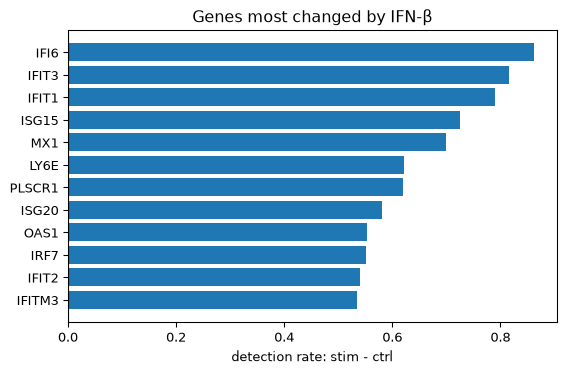

In [11]:
values_all = (
    nk_all.X.toarray() if hasattr(nk_all.X, "toarray") else np.asarray(nk_all.X)
)
is_ctrl = (nk_all.obs["condition"] == "ctrl").to_numpy()
is_stim = (nk_all.obs["condition"] == "stim").to_numpy()

detection = pd.DataFrame(
    {
        "ctrl": (values_all[is_ctrl] > 0).mean(axis=0),
        "stim": (values_all[is_stim] > 0).mean(axis=0),
    },
    index=nk_all.var_names,
)
detection["delta"] = detection["stim"] - detection["ctrl"]
top_changed = detection.reindex(
    detection["delta"].abs().sort_values(ascending=False).head(12).index
).sort_values("delta")

fig, ax = plt.subplots(figsize=(6, 4))
ax.barh(top_changed.index, top_changed["delta"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("detection rate: stim - ctrl")
ax.set_title("Genes most changed by IFN-β")
fig.tight_layout()
plt.show()

### 2.4 Expression matrix used for the capacities

EvoFlow consumes one row per cell and one column per gene. We export the
**stimulated** NK cells only, so percolation describes the treated state.

Subsetting before densifying keeps the exported file manageable. On larger
datasets, restrict the columns to the genes present in the annotation table
(`annotation_df["gene"]`): percolation is computed per gene, so unannotated
genes are never used.

In [12]:
is_stim = (nk_all.obs["condition"] == "stim").to_numpy()
nk_stim = nk_all[is_stim].copy()
print("stimulated NK cells:", nk_stim.n_obs, "| genes:", nk_stim.n_vars)

values = nk_stim.X.toarray() if hasattr(nk_stim.X, "toarray") else np.asarray(nk_stim.X)
expression_df = pd.DataFrame(values, index=nk_stim.obs_names, columns=nk_stim.var_names)
expression_path = INPUT_DIR / "kang_2018_nk_stim_expression.csv"
expression_df.to_csv(expression_path)
print("saved", expression_path, expression_df.shape)

stimulated NK cells: 861 | genes: 15706
saved /home/jovyan/work/vignettes/inputs/kang_2018_nk_stim_expression.csv (861, 15706)


### 2.5 Build the flow network

The low-level API follows the same steps as the reference pipeline:

1. load the network, annotation and expression data;
2. compute per-gene percolation;
3. build the graph and multiply each edge weight by the average percolation of
   its endpoints (`method="multiplicative"`);
4. add a `SuperSource` connected to the receptors and a `SuperSink` fed by the
   targets, turning the graph into a single source–sink max-flow problem.

`lock_targets=1` protects the original **source** nodes (the receptors): they are
the biological input of the model, so removing one would answer a different
question ("block the receptor") instead of "which intracellular mediator should
be targeted?". The targets are protected as well, because they are the read-out
whose remaining flow we are trying to reduce.

In [13]:
from EvoFlow.biology import BioNetworkPreparer

preparer = BioNetworkPreparer(lock_targets=1)
preparer.load_data(
    network_path=str(network_path),
    annotation_path=str(annotation_path),
    expression_path=str(expression_path),
)
preparer.compute_percolation(stat="mean")
preparer.build_base_network()
preparer.update_edge_capacities(method="multiplicative")

# Keep only the receptors/targets that made it into the inferred network.
receptors = [gene for gene in RECEPTORS if gene in preparer.G]
sinks_genes = [gene for gene in TARGETS if gene in preparer.G]
print("sources:", receptors)
print("sinks:", sinks_genes)
if not receptors or not sinks_genes:
    raise RuntimeError(
        "The NicheNet network contains none of the selected receptors/targets. "
        "Inspect the annotation table and adjust RECEPTORS/TARGETS."
    )

sources, sinks = preparer.prepare_bioflow_topology(
    receptors=receptors, target_genes=sinks_genes
)
network = preparer.G
print(f"graph: {network.number_of_nodes()} nodes, {network.number_of_edges()} edges")

Tue Nov 17 16:23:55 2026 - Reading files
Tue Nov 17 16:23:58 2026 - Creating network
sources: ['IFNAR1', 'IFNAR2']
sinks: ['ISG15', 'IFIT1', 'IFIT2', 'IFIT3', 'IFI6', 'MX1', 'MX2', 'OAS1', 'OAS2', 'OAS3', 'RSAD2', 'IFITM1', 'IFITM2', 'IFITM3']
graph: 170 nodes, 4980 edges


### 2.6 Run the genetic algorithm

The GA minimises three objectives at once:

- **Flow** — remaining maximum flow from receptors to targets; lower means a
  stronger functional knock-out;
- **Node** — number of removed mediators, i.e. the experimental cost;
- **Redundancy** — residual strongly connected components; fewer means the
  knock-out also dismantled the alternative routes.

The removal budget is 5% of the network (8 nodes here), which keeps the
hypothesis list small enough to test at the bench.

`delta_penalty=False` keeps every individual inside the budget, `repair=True`
fixes individuals that would overshoot it, and `dynamic=True` adapts the
mutation and crossover rates during the run to balance exploration and
exploitation. Multiprocessing is disabled so the notebook stays deterministic.

In [14]:
from EvoFlow.core import GAOptimizer

budget = max(2, int(round(0.05 * network.number_of_nodes())))
print("removal budget:", budget)

optimizer = GAOptimizer(
    network,
    sources,
    sinks,
    max_remove=budget,
    delta_penalty=False,  # keep every individual inside the budget
    repair=True,  # repair individuals that overshoot the budget
    dynamic=True,  # adapt mutation/crossover rates during the run
    use_multiprocessing=False,  # deterministic and safe inside Jupyter
)

evoflow_dir = OUTPUT_DIR / "evoflow" / SAMPLE
evoflow_dir.mkdir(parents=True, exist_ok=True)
previous_cwd = Path.cwd()
os.chdir(evoflow_dir)
try:
    results, logs, population, norm = optimizer.run(
        generations=200,
        population_size=150,
        early_stop_gen=50,
        guess_parameters=False,
        verbose=True,
    )
finally:
    os.chdir(previous_cwd)
print("optimization complete")

removal budget: 8
Tue Nov 17 16:23:58 2026 - Evaluating fitness for initial population...


/opt/conda/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


Tue Nov 17 16:23:58 2026 - Starting evolution for 200 generations
Tue Nov 17 16:23:58 2026 - Gen 0: Flow: 0.002, Nodes: 1.0, SCCs: 7569.0. HV: 7647.674
Tue Nov 17 16:23:58 2026 - Gen 1: Flow: 0.002, Nodes: 1.0, SCCs: 7569.0. HV: 7802.364
Tue Nov 17 16:23:59 2026 - Gen 2: Flow: 0.002, Nodes: 1.0, SCCs: 7569.0. HV: 8593.778
Tue Nov 17 16:23:59 2026 - Gen 3: Flow: 0.002, Nodes: 1.0, SCCs: 7569.0. HV: 8746.472
Tue Nov 17 16:23:59 2026 - Gen 4: Flow: 0.002, Nodes: 1.0, SCCs: 7396.0. HV: 9684.592
Tue Nov 17 16:23:59 2026 - Gen 5: Flow: 0.002, Nodes: 1.0, SCCs: 7396.0. HV: 10341.276
Tue Nov 17 16:23:59 2026 - Gen 6: Flow: 0.002, Nodes: 1.0, SCCs: 7396.0. HV: 10503.95
Tue Nov 17 16:24:00 2026 - Gen 7: Flow: 0.002, Nodes: 1.0, SCCs: 7396.0. HV: 11319.316
Tue Nov 17 16:24:00 2026 - Gen 8: Flow: 0.001, Nodes: 8.0, SCCs: 5776.0. HV: 11472.01
Tue Nov 17 16:24:00 2026 - Gen 9: Flow: 0.001, Nodes: 8.0, SCCs: 5776.0. HV: 12100.75
Tue Nov 17 16:24:00 2026 - Gen 10: Flow: 0.001, Nodes: 8.0, SCCs: 5776.0

### 2.7 Inspect the results

Each row of the summary is one point on the Pareto front:

- **`Flow`** — remaining maximum flow; lower is better.
- **`Node`** — number of removed mediators (the cost).
- **`Redundancy`** — residual strongly connected components.
- **`Best_balanced`** — the front point closest to the origin after
  per-objective normalisation, i.e. a good compromise.
- **`Best_Flow`**, **`Best_Cost`**, **`Best_Redundancy`** — the extreme points
  of the front, useful to see the trade-offs.

The `removed_nodes` column is the concrete hypothesis list to follow up.

In [15]:
rows = []
for solution, payload in results.items():
    row = {
        "solution": solution,
        "num_removed": payload["num_removed"],
        **{name: round(value, 3) for name, value in payload["fitness"].items()},
        "removed_nodes": ", ".join(payload["removed_nodes"]),
    }
    rows.append(row)
summary = pd.DataFrame(rows).set_index("solution")
display(summary)

,num_removed,Flow,Node,Redundancy,removed_nodes
solution,,,,,
Best_balanced,5,0.000,5.0,4904.0,"JAK1, STAT2, CD44, STAT1, STAT3"
Best_Flow,8,0.000,8.0,3029.0,"JAK1, FYN, STAT2, IRF1, CD44, STAT1, JUN, STAT3"
Best_Cost,1,0.002,1.0,7225.0,CD44
Best_Redundancy,8,0.002,8.0,2405.0,"JAK1, FYN, IRF1, CD44, YBX1, STAT1, LCK, JUN"


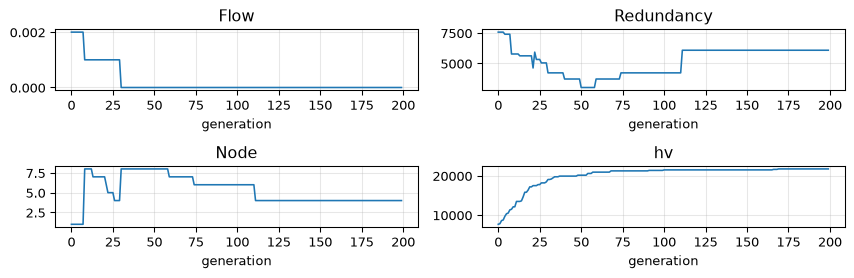

In [16]:
logs_df = pd.DataFrame(logs).T.reset_index(names="gen").sort_values("gen")
logs_df["gen"] = logs_df["gen"].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(9, 3))
for ax, metric in zip(axes.flatten(), ["Flow", "Redundancy", "Node", "hv"]):
    if metric in logs_df:
        ax.plot(logs_df["gen"], logs_df[metric], linewidth=1.2)
        ax.set_title(metric)
        ax.set_xlabel("generation")
        ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

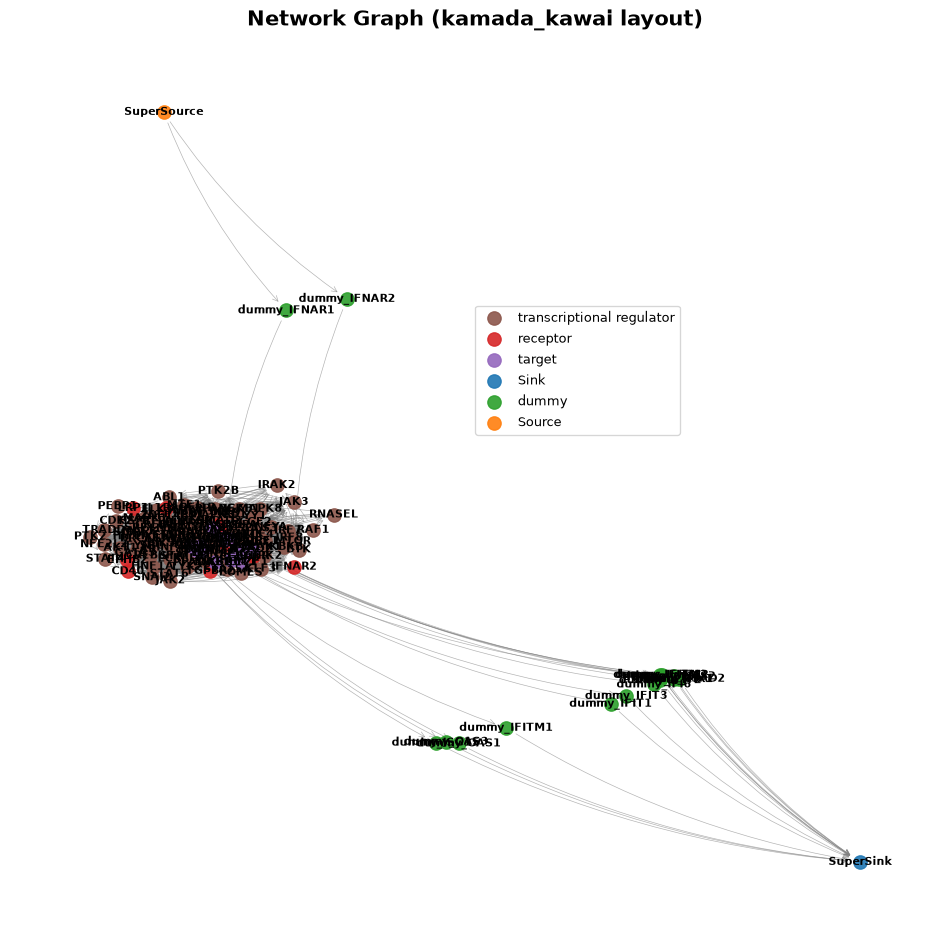

In [17]:
from EvoFlow.visualization import plot_graph

final_graph = optimizer.SG.copy()
final_graph.remove_nodes_from(results["Best_balanced"]["removed_nodes"])
fig, ax = plot_graph(
    final_graph,
    filename_prefix=None,
    layout="kamada_kawai",
    figsize=(10, 10),
    node_size=100,
)
plt.legend(loc="upper left", bbox_to_anchor=(0.5, 0.7), borderaxespad=0)
plt.show()

### 2.8 Interpreting the candidates

The receptors and the interferon-stimulated genes are protected, so every
reported gene is an intracellular mediator between IFNAR and the response. In
the run shown above:

| Solution | Genes | Reading |
| --- | --- | --- |
| `Best_balanced` | `JAK1`, `STAT2`, `CD44`, `STAT1`, `STAT3` | Core JAK–STAT components of type I IFN signalling plus CD44. |
| `Best_Flow` | `JAK1`, `FYN`, `STAT2`, `IRF1`, `CD44`, `STAT1`, `JUN`, `STAT3` | Adds the Src kinase FYN, IRF1 and AP-1 (JUN) to cut the response further. |
| `Best_Cost` | `CD44` | The single node whose removal already lowers flow, at minimum cost. |
| `Best_Redundancy` | `JAK1`, `FYN`, `IRF1`, `CD44`, `YBX1`, `STAT1`, `LCK`, `JUN` | Attacks the redundant routes rather than the shortest path. |

The result is reassuring: `JAK1` plus `STAT1`/`STAT2` is the canonical IFN-β
pathway (JAK1 phosphorylates the IFNAR tails, then STAT1 and STAT2 assemble
ISGF3 with IRF9), so the algorithm recovered known biology from topology and
expression alone. `STAT3` is a well-described secondary STAT activated by type I
interferon, and `JUN` (AP-1) is a downstream synergy node.

The interesting non-canonical hit is **`CD44`**, the adhesion molecule and
co-receptor of receptor tyrosine kinases, expressed in all immune cells
([PLOS ONE](https://journals.plos.org/plosone/article?id=10.1371/journal.pone.0207358)).
That study also reports IFN-β–dependent upregulation of CD44, which makes it a
plausible modulator rather than an artefact: it appears in every solution, and
because `Best_Cost` needs only CD44 to lower the flow, it is the cheapest
testable hypothesis.

**Take-home.** A five-node knock-out centred on JAK1/STAT1/STAT2 is enough to
collapse the interferon read-out in this network, and CD44 is flagged as a
cheap, non-canonical candidate worth a perturbation experiment.

## 3. Use case B — NK activation and effector program

The second question zooms out from one cytokine to the **effector arm of the NK
cell**: which mediators connect the receptors NK cells use to sense other cells
to the granule and cytokine genes that actually kill targets?

### 3.1 Receptor and target panel

| Gene(s) | Role |
| --- | --- |
| `NCR1`, `NCR3` | Natural cytotoxicity receptors (NKp46, NKp30) — activating. |
| `KLRK1`, `KLRD1` | NKG2D (activating) and CD94 (partner of NKG2A, inhibitory): the balance that sets the activation threshold. |
| `CD244`, `SLAMF6` | SLAM-family co-receptors that tune NK education and cytotoxicity. |
| `CD96`, `CD226`, `TIGIT` | The DNAM-1/TIGIT axis competing for the same ligands (`PVR`, `NECTIN2`). |
| `HAVCR2`, `PDCD1`, `LAG3` | Inhibitory checkpoints expressed by activated or exhausted NK cells. |
| `FCGR3A` | CD16, the FcγRIIIa that mediates antibody-dependent cellular cytotoxicity. |
| `NKG7`, `GNLY`, `PRF1`, `GZMB`, `GZMH`, `CTSW` | Granule and lytic effectors: the functional output of an activated NK cell. |
| `IFNG`, `TNF` | Cytokines secreted on activation. |

> `NCR2`, `FCGR3A` and `SLAMF6` are kept in the CSV for completeness but do not
> appear in NicheNet's human ligand–receptor network. EvoFlow prints which
> receptors survive, and those three are dropped automatically.

In [ ]:
nk_endpoints = pd.read_csv("inputs/nk_activation_effector_endpoints_unique.csv")

As before, edit the CSV to explore a different panel. Deriving the ligands from
these receptors brings in MHC class I (NKG2/CD94 ligands), stress ligands
(`MICA`, `MICB`, `ULBP2`, `RAET1E`), the DNAM-1/TIGIT ligands (`PVR`,
`NECTIN2`) and checkpoint ligands (`LGALS9`, `CD274`).

### 3.2 Build the prior

The panel is larger, so with the same `top_n_regulators=10` the inferred network
is larger too (about 20,000 edges and 400 nodes): more receptors mean more
ligands, and more ligands mean more alternative routes. That is exactly the
redundancy the GA has to deal with, and it makes this a useful stress test for
the method.

In [20]:
SAMPLE = "nk_activation"

# Receptors that sample the activating and inhibitory input of an NK cell.
RECEPTORS = list(nk_endpoints["receptors"].dropna().values)

# Granule, cytokine and cytotoxic effectors used as read-outs.
TARGETS = list(nk_endpoints["targets"].dropna().values)

In [21]:
with open(reference_dir / "ltf_matrix_human.pkl", "rb") as handle:
    ltf = pickle.load(handle)
with open(reference_dir / "nichenet_human.pkl", "rb") as handle:
    model = pickle.load(handle)

lr_sig = pd.DataFrame(model["lr_sig"]._mapping, columns=["from", "to", "weight"])
gr = pd.DataFrame(model["gr"]._mapping, columns=["from", "to", "weight"])
lr_network = pd.DataFrame(model["lr_network"]._mapping, columns=["from", "to"])

ligands = sorted(set(lr_network.loc[lr_network["to"].isin(RECEPTORS), "from"]))
gr_targets = set(gr["to"].unique())
targets = [target for target in TARGETS if target in gr_targets]
print(f"{len(ligands)} candidate ligands: {ligands}")
print(f"targets kept: {targets}")
if not ligands or not targets:
    raise RuntimeError(
        "No ligands or targets remain for the selected receptors. "
        "Adjust RECEPTORS/TARGETS."
    )

51 candidate ligands: ['ACE2', 'B2M', 'CD274', 'CD48', 'CD79B', 'CEACAM1', 'CFP', 'CLEC4G', 'EGFL8', 'FAM3C', 'FGL1', 'HLA-A', 'HLA-B', 'HLA-DPB1', 'HLA-DQA1', 'HLA-DQA2', 'HLA-DQB1', 'HLA-DQB2', 'HLA-DRA', 'HLA-DRB1', 'HLA-DRB3', 'HLA-DRB4', 'HLA-DRB5', 'HLA-E', 'HLA-G', 'HMGB1', 'ITGAL', 'ITGB2', 'LGALS3', 'LGALS9', 'MCAM', 'MICA', 'MICB', 'NAALADL1', 'NCR3LG1', 'NECTIN1', 'NECTIN2', 'NECTIN3', 'NECTIN4', 'PDCD1LG2', 'PVR', 'RAET1E', 'RAET1G', 'RECK', 'SIGLEC6', 'SIGLEC7', 'SIGLEC8', 'SIRPA', 'TYROBP', 'ULBP2', 'ULBP3']
targets kept: ['NKG7', 'GNLY', 'PRF1', 'GZMB', 'GZMH', 'CTSW', 'IFNG', 'TNF']


In [22]:
tf_signaling, tf_regulatory = get_ligand_signaling_path(
    ltf["mat"],
    ligands,
    targets,
    all_ligands=ltf["row_names"],
    all_targets=ltf["col_names"],
    lr_sig=lr_sig,
    gr=gr,
    top_n_regulators=10,
    minmax_scaling=False,
)

network_df = pd.concat(
    [
        tf_signaling.assign(layer="signaling"),
        tf_regulatory.assign(layer="regulatory"),
    ],
    ignore_index=True,
)
network_nodes = set(network_df["from"]) | set(network_df["to"])
print(f"net: {len(network_df)} edges, {len(network_nodes)} nodes")
print("receptors in network:", [r for r in RECEPTORS if r in network_nodes])
print("targets in network:", [t for t in targets if t in network_nodes])
display(network_df.head())

net: 20761 edges, 421 nodes
receptors in network: ['NCR1', 'NCR3', 'KLRD1', 'KLRK1', 'CD244', 'CD96', 'CD226', 'TIGIT', 'HAVCR2', 'PDCD1', 'LAG3']
targets in network: ['NKG7', 'GNLY', 'PRF1', 'GZMB', 'GZMH', 'CTSW', 'IFNG', 'TNF']


,from,to,weight,layer
0,A1CF,FHL2,0.203795,signaling
1,A1CF,HNF1A,0.132233,signaling
2,A1CF,HNF4A,0.112374,signaling
3,A1CF,JUN,0.194797,signaling
4,A1CF,MAX,0.075818,signaling


The annotation step is identical for any panel: label every node by type, then
save the network and annotation tables. Only the file prefix (`SAMPLE`) changes,
so the two use cases do not overwrite each other on disk.

In [23]:
receptor_genes = set(lr_network["to"])
regulator_genes = set(gr["from"])
ligand_set, target_set = set(ligands), set(targets)

rows = []
for gene in sorted(network_nodes):
    if gene in ligand_set:
        annotation = "ligand"
    elif gene in target_set:
        annotation = "target"
    elif gene in receptor_genes:
        annotation = "receptor"
    elif gene in regulator_genes:
        annotation = "transcriptional regulator"
    else:
        annotation = "signaling mediator"
    rows.append({"gene": gene, "annotation": annotation})
annotation_df = pd.DataFrame(rows)

network_path = NICHENET_DIR / f"{SAMPLE}_weighted_signaling_network.tsv"
annotation_path = NICHENET_DIR / f"{SAMPLE}_annotation_table.tsv"
network_df.to_csv(network_path, sep="\t", index=False)
annotation_df.to_csv(annotation_path, sep="\t", index=False)

print("saved", network_path.name, "and", annotation_path.name)
display(annotation_df["annotation"].value_counts())

annotation
transcriptional regulator    253
receptor                      93
ligand                        51
signaling mediator            16
target                         8
Name: count, dtype: int64

### 3.3 Expression matrix

The same stimulated NK cells are used; only the prior changes. Percolation is
computed per gene, so the two analyses share the cell state and differ only in
the network they interrogate.

In [25]:
is_stim = (nk_all.obs["condition"] == "stim").to_numpy()
nk_stim = nk_all[is_stim].copy()
print("stimulated NK cells:", nk_stim.n_obs, "| genes:", nk_stim.n_vars)

values = nk_stim.X.toarray() if hasattr(nk_stim.X, "toarray") else np.asarray(nk_stim.X)
expression_df = pd.DataFrame(values, index=nk_stim.obs_names, columns=nk_stim.var_names)
expression_path = INPUT_DIR / "kang_2018_nk_stim_expression.csv"
expression_df.to_csv(expression_path)
print("saved", expression_path, expression_df.shape)

stimulated NK cells: 861 | genes: 15706
saved /home/jovyan/work/vignettes/inputs/kang_2018_nk_stim_expression.csv (861, 15706)


### 3.4 Build the flow network

Nothing changes from use case A: load the network, compute percolation, build
the capacities, protect sources and targets, and add the `SuperSource` /
`SuperSink` topology. Note that the two graphs are independent objects — the
second `BioNetworkPreparer` does not modify the first one.

In [26]:
from EvoFlow.biology import BioNetworkPreparer

preparer = BioNetworkPreparer(lock_targets=1)
preparer.load_data(
    network_path=str(network_path),
    annotation_path=str(annotation_path),
    expression_path=str(expression_path),
)
preparer.compute_percolation(stat="mean")
preparer.build_base_network()
preparer.update_edge_capacities(method="multiplicative")

# Keep only the receptors/targets that made it into the inferred network.
receptors = [gene for gene in RECEPTORS if gene in preparer.G]
sinks_genes = [gene for gene in TARGETS if gene in preparer.G]
print("sources:", receptors)
print("sinks:", sinks_genes)
if not receptors or not sinks_genes:
    raise RuntimeError(
        "The NicheNet network contains none of the selected receptors/targets. "
        "Inspect the annotation table and adjust RECEPTORS/TARGETS."
    )

sources, sinks = preparer.prepare_bioflow_topology(
    receptors=receptors, target_genes=sinks_genes
)
network = preparer.G
print(f"graph: {network.number_of_nodes()} nodes, {network.number_of_edges()} edges")

Tue Nov 17 16:25:52 2026 - Reading files
Tue Nov 17 16:25:55 2026 - Creating network
sources: ['NCR1', 'NCR3', 'KLRD1', 'KLRK1', 'CD244', 'CD96', 'CD226', 'TIGIT', 'HAVCR2', 'PDCD1', 'LAG3']
sinks: ['NKG7', 'GNLY', 'PRF1', 'GZMB', 'GZMH', 'CTSW', 'IFNG', 'TNF']
graph: 442 nodes, 20799 edges


### 3.5 Run the genetic algorithm

As before, the GA trades off **flow**, **number of removed nodes** and
**redundancy**, with a removal budget of 2% of the network (9 nodes here).

This time the GA parameters are **not** fixed: `guess_parameters=True` asks the
bundled GAM to predict a population size and an early-stopping patience from
four network features (search-space size, degree exponent, density and
clustering coefficient). Here it proposes population 50 and patience 100. Letting
the model choose is the recommended setting for a new network, whereas fixing
the values keeps a run short and exactly reproducible.

In [27]:
from EvoFlow.core import GAOptimizer

budget = max(2, int(round(0.02 * network.number_of_nodes())))
print("removal budget:", budget)

optimizer = GAOptimizer(
    network,
    sources,
    sinks,
    max_remove=budget,
    delta_penalty=False,  # keep every individual inside the budget
    repair=True,  # repair individuals that overshoot the budget
    dynamic=True,  # adapt mutation/crossover rates during the run
    use_multiprocessing=False,  # deterministic and safe inside Jupyter
)

evoflow_dir = OUTPUT_DIR / "evoflow" / SAMPLE
evoflow_dir.mkdir(parents=True, exist_ok=True)
previous_cwd = Path.cwd()
os.chdir(evoflow_dir)
try:
    results, logs, population, norm = optimizer.run(
        guess_parameters=True,
        verbose=True,
    )
finally:
    os.chdir(previous_cwd)
print("optimization complete")

removal budget: 9
Guessed parameters:
Population = 50
Early_stop_gen = 100
Tue Nov 17 16:25:56 2026 - Evaluating fitness for initial population...
Tue Nov 17 16:25:56 2026 - Starting evolution for 1000 generations


/opt/conda/lib/python3.13/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_array is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


Tue Nov 17 16:25:56 2026 - Gen 0: Flow: 0.007, Nodes: 5.0, SCCs: 78961.0. HV: 36613.553
Tue Nov 17 16:25:57 2026 - Gen 1: Flow: 0.007, Nodes: 4.0, SCCs: 79524.0. HV: 37151.926
Tue Nov 17 16:25:57 2026 - Gen 2: Flow: 0.006, Nodes: 9.0, SCCs: 77841.0. HV: 37152.483
Tue Nov 17 16:25:57 2026 - Gen 3: Flow: 0.006, Nodes: 9.0, SCCs: 77841.0. HV: 47721.251
Tue Nov 17 16:25:57 2026 - Gen 4: Flow: 0.006, Nodes: 6.0, SCCs: 79524.0. HV: 56437.608
Tue Nov 17 16:25:57 2026 - Gen 5: Flow: 0.006, Nodes: 6.0, SCCs: 79524.0. HV: 98047.859
Tue Nov 17 16:25:58 2026 - Gen 6: Flow: 0.006, Nodes: 6.0, SCCs: 79524.0. HV: 99613.607
Tue Nov 17 16:25:58 2026 - Gen 7: Flow: 0.006, Nodes: 4.0, SCCs: 70756.0. HV: 101203.443
Tue Nov 17 16:25:58 2026 - Gen 8: Flow: 0.006, Nodes: 4.0, SCCs: 70756.0. HV: 101205.074
Tue Nov 17 16:25:58 2026 - Gen 9: Flow: 0.006, Nodes: 4.0, SCCs: 70756.0. HV: 111435.636
Tue Nov 17 16:25:58 2026 - Gen 10: Flow: 0.005, Nodes: 9.0, SCCs: 67600.0. HV: 112997.625
Tue Nov 17 16:25:59 2026 - 

### 3.6 Inspect the results

The same four Pareto points as before, now for the NK effector program. With a
larger and more redundant network, the flow values are higher and the solutions
contain more nodes, but the interpretation is unchanged.

In [28]:
rows = []
for solution, payload in results.items():
    row = {
        "solution": solution,
        "num_removed": payload["num_removed"],
        **{name: round(value, 3) for name, value in payload["fitness"].items()},
        "removed_nodes": ", ".join(payload["removed_nodes"]),
    }
    rows.append(row)
summary = pd.DataFrame(rows).set_index("solution")
display(summary)

,num_removed,Flow,Node,Redundancy,removed_nodes
solution,,,,,
Best_balanced,6,0.004,6.0,66049.0,"UBB, NKG7, CTSW, GNLY, PTPRC, TNF"
Best_Flow,7,0.001,7.0,81225.0,"NKG7, IFNG, CTSW, GZMH, GNLY, GZMB, TNF"
Best_Cost,1,0.007,1.0,81225.0,CTSW
Best_Redundancy,9,0.008,9.0,39605.0,"UBB, TYROBP, PTPRC, NR3C1, FYN, UBE2I, CD44, N..."


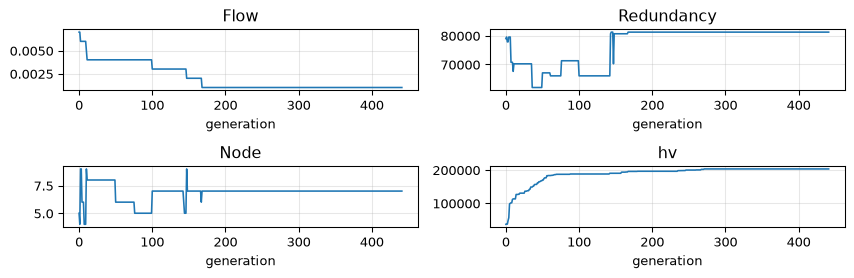

In [29]:
logs_df = pd.DataFrame(logs).T.reset_index(names="gen").sort_values("gen")
logs_df["gen"] = logs_df["gen"].astype(int)

fig, axes = plt.subplots(2, 2, figsize=(9, 3))
for ax, metric in zip(axes.flatten(), ["Flow", "Redundancy", "Node", "hv"]):
    if metric in logs_df:
        ax.plot(logs_df["gen"], logs_df[metric], linewidth=1.2)
        ax.set_title(metric)
        ax.set_xlabel("generation")
        ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

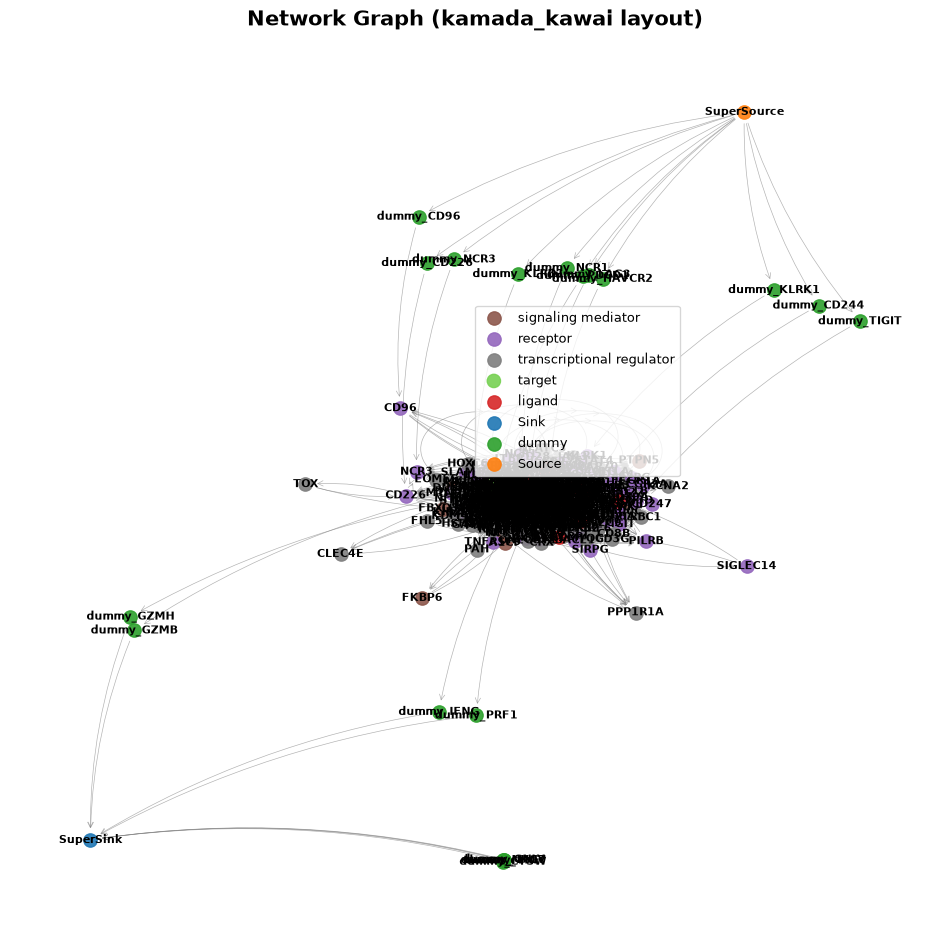

In [30]:
from EvoFlow.visualization import plot_graph

final_graph = optimizer.SG.copy()
final_graph.remove_nodes_from(results["Best_balanced"]["removed_nodes"])
fig, ax = plot_graph(
    final_graph,
    filename_prefix=None,
    layout="kamada_kawai",
    figsize=(10, 10),
    node_size=100,
)
plt.legend(loc="upper left", bbox_to_anchor=(0.5, 0.7), borderaxespad=0)
plt.show()

### 3.7 Interpreting the candidates

| Solution | Genes | Reading |
| --- | --- | --- |
| `Best_balanced` | `UBB`, `NKG7`, `CTSW`, `GNLY`, `PTPRC`, `TNF` | Effector arm plus two signalling/ubiquitin nodes. |
| `Best_Flow` | `NKG7`, `IFNG`, `CTSW`, `GZMH`, `GNLY`, `GZMB`, `TNF` | The granule/cytokine block alone: removing it nearly eliminates flow to the read-out. |
| `Best_Cost` | `CTSW` | The cheapest single-node intervention. |
| `Best_Redundancy` | `UBB`, `TYROBP`, `PTPRC`, `NR3C1`, `FYN`, `UBE2I`, `CD44`, … (9 nodes) | Attacks the redundant signalling core rather than the output itself. |

The solutions group into a few coherent stories:

| Functional axis | Genes | Integrated role in IFN-β–stimulated NK cells |
| --- | --- | --- |
| **Cytotoxic granule and NK lineage** | `GNLY`, `NKG7`, `CTSW` | `GNLY` is the pore-forming protein stored in lytic granules; `NKG7` drives granule exocytosis at the immune synapse; `CTSW` (cathepsin W) marks mature cytotoxic NK cells and supports granule function. |
| **Cytokine / death-receptor arm** | `TNF` | Provides non-granule target killing and inflammatory amplification, and feeds back on type I IFN/STAT1 signalling. |
| **Receptor-proximal signalling** | `PTPRC` (CD45) | Licenses ITAM/Src-kinase signalling required for `TNF` production and `NKG7`-mediated degranulation, while acting as a JAK phosphatase brake on IFNAR signalling. |
| **Ubiquitin and scaffold** | `UBB`, `UBE2I`, `TYROBP` | Free ubiquitin and conjugating enzymes are needed for IFNAR1 endocytosis/turnover and for TNF–NF-κB signalling (polyubiquitin chains on RIPK1/TRAF/NEMO); `TYROBP` (DAP12) carries the ITAM signal of activating NK receptors. |

`Best_Flow` is biologically the cleanest result: the seven genes it removes are
almost exactly the granule and cytokine output itself, which is what a max-flow
min-cut must find when the read-out *is* the effector program. The
`Best_balanced` and `Best_Redundancy` solutions are more interesting
experimentally, because they reach the same functional block through signalling
and ubiquitin nodes that are shared with the interferon response (`PTPRC`,
`UBB`, `CD44`).

**Take-home.** Removing the effector genes themselves trivially lowers the
read-out; the actionable hypotheses are the shared mediators (`PTPRC`, `UBB`,
`TYROBP`), which couple NK activation to the IFN-β response and could modulate
both at once.

## Alternative: the one-call CLI / Python API

For production runs the same pipeline is available through
`EvoFlow.cli.run_evoflow` and the `evoflow` console script. It also handles
h5ad cell-type filtering, bulk expression files and automatic output naming:

```python
from EvoFlow.cli import run_evoflow

run_evoflow(
    network=str(network_path),
    annotation=str(annotation_path),
    expression_file=str(expression_path),
    receptors_raw="IFNAR1|IFNAR2|IL2RB|IL15RA",
    mediators_raw="STAT1,STAT2,IRF9,TBX21,EOMES",
    targets="ISG15,IFIT1,MX1,IFITM1",  # or a regulons file
    generations=2000,
)
```

Use the low-level API shown above when you already have pre-processed inputs or
want to keep the `GAOptimizer` object (for example to inspect the active
subgraph or to pickle it for later runs). The full CLI reference is in the
API documentation.

## Reproducing and saving this notebook

1. Build or pull the container described in the container documentation.
2. Open `vignettes/use_case.ipynb` in JupyterLab and run all cells
   (`Run > Run All Cells`); the first run downloads about 640 MB of reference
   data and takes a few minutes per use case.
3. Save the notebook (`File > Save and Checkpoint`) before publishing a release.

Only `inputs/ifn_response_endpoints_unique.csv` and
`inputs/nk_activation_effector_endpoints_unique.csv` are committed. The
exported expression matrix, the inferred networks and the GA logs are
written next to the notebook under `inputs/` and `outputs/`, and are ignored
by git. All figures are already configured at 96 DPI with small figure
sizes, so the committed notebook stays small.